# Minsk Rental Market Analysis

Analysis of long-term apartment rental listings in Minsk based on a fresh market snapshot collected from Realt.by.

The project explores rental prices, location effects, apartment characteristics, seller type, and recorded price changes.

## 1. Data Loading and Preparation

The analysis uses two datasets:

- `listings_2026-10-28.csv` — current rental listings with apartment characteristics, location, prices, and seller information;
- `price_history_2026-10-28.csv` — recorded price history for the collected listings.

The datasets were collected on October 28, 2026 using the custom Realt.by collector included in this repository.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path("data")

listings = pd.read_csv(DATA_DIR / "listings_2026-10-28.csv")
price_history = pd.read_csv(DATA_DIR / "price_history_2026-10-28.csv")

print("Listings shape:", listings.shape)
print("Price history shape:", price_history.shape)

Listings shape: (1624, 31)
Price history shape: (4665, 7)


### Initial Inspection

Before analysis, the datasets are checked for structure, data types, missing values, and duplicate records.

In [2]:
print("Listings:")
display(listings.head())

print("\nPrice history:")
display(price_history.head())

Listings:


,ad_code,ad_uuid,collected_at,listed_price,listed_currency,price_byn,price_usd,price_change_date,price_change_direction,rooms,...,metro_station,metro_time_min,metro_time_mode,district,subdistrict,created_at,updated_at,raise_date,new_again_date,seller_type
0,4230328,59214910-ad18-11f1-9c1a-db8dd9ac123b,2026-10-28T11:47:44.953476+03:00,1960,BYN,1960,665,2026-10-12T10:04:00+03:00,down,2,...,NaN,NaN,NaN,Советский район,"Я.Коласа-Рига, Некрасова, Восточная",2026-09-10T16:05:51+03:00,2026-10-12T10:04:04+03:00,2026-10-27T14:34:09+03:00,2026-09-10T16:05:51+03:00,private
1,4246065,3b9d00b0-bcdf-11f1-8434-6fe1437f6a99,2026-10-28T11:47:44.953476+03:00,1500,USD,4418,1500,2026-10-25T11:29:34+03:00,down,3,...,Грушевка,1.0,NaN,Московский район,"Р.Люксембург, К.Либкнехта",2026-09-30T17:57:18+03:00,2026-10-25T12:12:43+03:00,2026-10-28T09:06:35+03:00,2026-09-30T17:57:18+03:00,private
2,4093327,da5e8493-359d-11f1-b04f-b295db31e5cb,2026-10-28T11:47:44.953476+03:00,7358,BYN,7358,2498,2026-10-27T12:27:35+03:00,down,3,...,NaN,NaN,NaN,Центральный район,Лебяжий (Ржавец),2026-04-11T14:59:11+03:00,2026-10-27T12:27:35+03:00,2026-10-27T19:32:54+03:00,2026-04-11T14:59:11+03:00,agency
3,3867217,897c0a70-843b-11f0-b4d2-d11de0c5f6b0,2026-10-28T11:47:44.953476+03:00,600,USD,1767,600,2026-10-24T10:53:26+03:00,up,1,...,Аэродромная (2024),5.0,NaN,Октябрьский район,Минск Мир (Minsk World),2025-08-28T21:19:29+03:00,2026-10-24T11:42:45+03:00,2026-10-28T10:53:26+03:00,2025-09-01T09:02:46+03:00,private
4,3861286,0ef7f3a0-7f99-11f0-b502-3118c2301b87,2026-10-28T11:47:44.953476+03:00,600,USD,1767,600,2026-09-08T13:42:14+03:00,up,2,...,Пролетарская,4.0,NaN,Ленинский район,"нач.Партизанского, пл.Ванеева",2025-08-22T23:46:20+03:00,2026-10-28T09:18:45+03:00,2026-10-28T09:18:45+03:00,2026-10-28T09:18:45+03:00,private



Price history:


,ad_code,recorded_at,price_currency,price_listed,price_byn,price_usd,status
0,4230328,2026-10-12T10:04:00+03:00,BYN,1960.0,1960.0,665.0,-1
1,4230328,2026-09-10T16:07:37+03:00,BYN,2250.0,2250.0,764.0,0
2,4246065,2026-10-25T11:29:34+03:00,USD,1500.0,4418.0,1500.0,-1
3,4246065,2026-10-04T16:43:41+03:00,USD,1700.0,5008.0,1700.0,-1
4,4246065,2026-10-01T17:31:40+03:00,USD,2000.0,5891.0,2000.0,1


In [3]:
print("Listings info:")
listings.info()

print("\nPrice history info:")
price_history.info()

Listings info:
<class 'pandas.DataFrame'>
RangeIndex: 1624 entries, 0 to 1623
Data columns (total 31 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ad_code                 1624 non-null   int64  
 1   ad_uuid                 1624 non-null   str    
 2   collected_at            1624 non-null   str    
 3   listed_price            1624 non-null   int64  
 4   listed_currency         1624 non-null   str    
 5   price_byn               1624 non-null   int64  
 6   price_usd               1624 non-null   int64  
 7   price_change_date       894 non-null    str    
 8   price_change_direction  892 non-null    str    
 9   rooms                   1624 non-null   int64  
 10  area_total_m2           1623 non-null   float64
 11  area_living_m2          1605 non-null   float64
 12  area_kitchen_m2         640 non-null    float64
 13  floor                   1624 non-null   int64  
 14  floors_total            1624 non-nul

In [4]:
print("Duplicate listing IDs:", listings["ad_code"].duplicated().sum())

print(
    "Duplicate price history records:",
    price_history.duplicated(
        subset=["ad_code", "recorded_at"]
    ).sum(),
)

Duplicate listing IDs: 0
Duplicate price history records: 0


### Data Type Conversion

Timestamp columns are converted from strings to pandas datetime objects to enable time-based analysis.

In [5]:
listing_datetime_columns = [
    "collected_at",
    "price_change_date",
    "created_at",
    "updated_at",
    "raise_date",
    "new_again_date",
]

for column in listing_datetime_columns:
    listings[column] = pd.to_datetime(
        listings[column],
        errors="coerce",
        utc=True,
    )

price_history["recorded_at"] = pd.to_datetime(
    price_history["recorded_at"],
    errors="coerce",
    utc=True,
)

### Missing Value Review

Critical missing values are inspected before applying any cleaning rules.

In [6]:
print("Listings without total area:", listings["area_total_m2"].isna().sum())
print(
    "Price history records without prices:",
    price_history["price_listed"].isna().sum(),
)

Listings without total area: 1
Price history records without prices: 2


Two price history records contain no price values and cannot be used for price change analysis. These records are removed, while listings with partially missing apartment characteristics are retained whenever they remain useful for other parts of the analysis.

In [7]:
price_history = price_history.dropna(
    subset=["price_listed", "price_byn", "price_usd"]
).copy()

print("Price history shape after cleaning:", price_history.shape)

Price history shape after cleaning: (4663, 7)


### Numerical Data Validation

Key numerical fields are reviewed for implausible values and extreme observations before feature engineering and market analysis.

In [8]:
numeric_columns = [
    "price_usd",
    "rooms",
    "area_total_m2",
    "area_living_m2",
    "area_kitchen_m2",
    "floor",
    "floors_total",
    "building_year",
    "metro_time_min",
]

listings[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
price_usd,1624.0,838.558498,476.187557,153.0,570.000,700.0,950.00,5585.0
rooms,1624.0,2.104680,0.898484,1.0,1.000,2.0,3.00,5.0
area_total_m2,1623.0,62.908694,33.744500,24.1,43.000,55.0,71.95,420.0
area_living_m2,1605.0,42.751059,23.596527,5.0,29.000,38.0,51.00,330.0
area_kitchen_m2,640.0,11.178969,6.463076,3.0,7.685,10.0,12.30,73.0
floor,1624.0,7.487069,5.663044,1.0,3.000,6.0,10.00,33.0
floors_total,1624.0,13.073276,7.208038,1.0,8.000,10.0,19.00,37.0
building_year,1282.0,2004.078783,21.522442,1917.0,1994.000,2013.0,2020.00,2026.0
metro_time_min,574.0,6.832753,4.475246,1.0,3.000,5.0,10.00,20.0


### Handling Implausible Values

Clearly impossible structural values are replaced with missing values rather than removing entire listings. Unusually low rental prices are retained because they cannot be confidently identified as data errors without additional listing context.

In [9]:
snapshot_year = listings["collected_at"].dt.year.max()

invalid_floor_mask = listings["floor"] > listings["floors_total"]
invalid_year_mask = listings["building_year"] > snapshot_year

print("Invalid floor values:", invalid_floor_mask.sum())
print("Future building years:", invalid_year_mask.sum())

listings.loc[invalid_floor_mask, "floor"] = pd.NA
listings.loc[invalid_year_mask, "building_year"] = pd.NA

Invalid floor values: 1
Future building years: 0


### Feature Engineering

A derived metric is created for the analysis:

- `price_per_m2_usd` — monthly rent per square meter in USD.

In [10]:
listings["price_per_m2_usd"] = (
    listings["price_usd"] / listings["area_total_m2"]
)

In [11]:
listings["price_per_m2_usd"].describe()

count    1623.000000
mean       14.003473
std         5.048098
min         2.125000
25%        10.527756
50%        13.076923
75%        16.317702
max        56.867672
Name: price_per_m2_usd, dtype: float64

### Categorical Data Review

Selected categorical features are inspected to identify inconsistent source values before grouping and visualization.

In [12]:
categorical_columns = [
    "repair_state",
    "district",
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(listings[column].value_counts(dropna=False))


repair_state:
repair_state
euro                955
good                428
normal              105
NaN                  99
отличный             34
плохое состояние      3
Name: count, dtype: int64

district:
district
Центральный район     332
Октябрьский район     265
Первомайский район    229
Фрунзенский район     217
Московский район      205
Советский район       166
Ленинский район        88
Партизанский район     60
Заводской район        40
NaN                    19
Сокол                   1
Запад, Красный Бор      1
Макаенка                1
Name: count, dtype: int64


### Categorical Normalization

A small number of categorical values are standardized for consistent analysis. Non-district values found in the district field are treated as missing because they do not represent Minsk administrative districts.

In [13]:
valid_districts = {
    "Центральный район",
    "Октябрьский район",
    "Первомайский район",
    "Фрунзенский район",
    "Московский район",
    "Советский район",
    "Ленинский район",
    "Партизанский район",
    "Заводской район",
}

listings.loc[
    ~listings["district"].isin(valid_districts)
    & listings["district"].notna(),
    "district",
] = pd.NA

district_map = {
    "Центральный район": "Central",
    "Октябрьский район": "Oktyabrsky",
    "Первомайский район": "Pervomaisky",
    "Фрунзенский район": "Frunzensky",
    "Московский район": "Moskovsky",
    "Советский район": "Sovetsky",
    "Ленинский район": "Leninsky",
    "Партизанский район": "Partizansky",
    "Заводской район": "Zavodskoy",
}

listings["district"] = listings["district"].replace(
    district_map
)

repair_state_map = {
    "отличный": "excellent",
    "плохое состояние": "poor",
    "удовлетворительный": "satisfactory",
}

listings["repair_state"] = listings["repair_state"].replace(
    repair_state_map
)

In [14]:
print("District categories:", listings["district"].nunique())
print("Missing districts:", listings["district"].isna().sum())
print(
    "Repair states:",
    sorted(listings["repair_state"].dropna().unique()),
)

District categories: 9
Missing districts: 22
Repair states: ['euro', 'excellent', 'good', 'normal', 'poor']


## 2. Market Overview

The analysis begins with a high-level view of the current Minsk long-term rental market, focusing on rental prices, apartment size, and room count.

In [15]:
market_overview = pd.Series(
    {
        "Listings": len(listings),
        "Median rent, USD": listings["price_usd"].median(),
        "Median rent per m², USD": listings["price_per_m2_usd"].median(),
        "Median apartment area, m²": listings["area_total_m2"].median(),
        "Median rooms": listings["rooms"].median(),
        "Private listings, %": (
            listings["seller_type"].eq("private").mean() * 100
        ),
    }
)

market_overview.round(1)

Listings                     1624.0
Median rent, USD              700.0
Median rent per m², USD        13.1
Median apartment area, m²      55.0
Median rooms                    2.0
Private listings, %            76.8
dtype: float64

### Rental Price Distribution

The rental market is right-skewed, with most listings concentrated in the mid-price segment and a smaller number of premium apartments extending the upper tail.

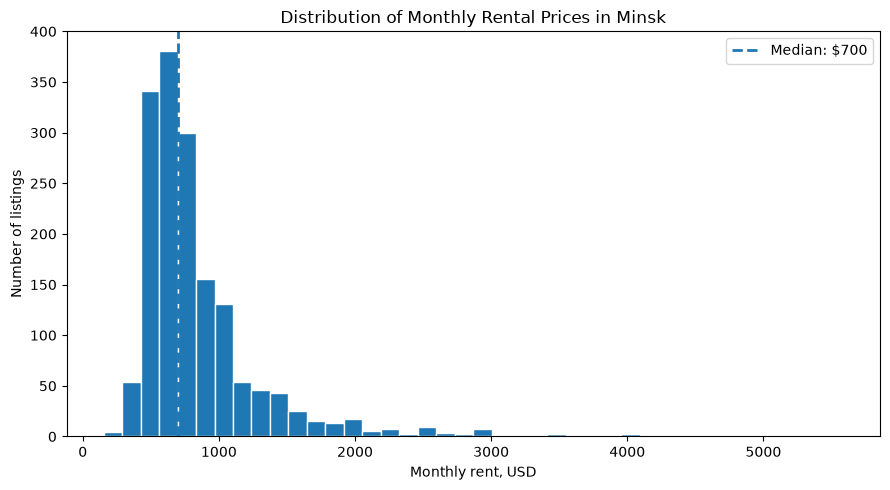

In [16]:
median_rent = listings["price_usd"].median()

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    listings["price_usd"],
    bins=40,
    edgecolor="white",
)

ax.axvline(
    median_rent,
    linestyle="--",
    linewidth=2,
    label=f"Median: ${median_rent:,.0f}",
)

ax.set_title("Distribution of Monthly Rental Prices in Minsk")
ax.set_xlabel("Monthly rent, USD")
ax.set_ylabel("Number of listings")
ax.legend()

plt.tight_layout()
plt.show()

The median monthly rent is **\$700**. The distribution is right-skewed: most listings are concentrated below the premium segment, while a relatively small number of high-priced apartments extend the upper tail.

Median values are used as the primary measure of central tendency throughout the analysis because high-priced listings would disproportionately affect the mean.

### Sensitivity to Outliers

The sensitivity of mean and median monthly asking rent to unusually priced listings is examined using two statistical filters. Flagged listings are treated as potential outliers rather than confirmed data errors.

- **IQR of asking rent:** prices outside `Q1 − 1.5 × IQR` and `Q3 + 1.5 × IQR` are excluded from the comparison.
- **Log-MAD within room-count groups:** the modified z-score is calculated as `0.67448975 × abs(log(price) − median(log(price))) / MAD`. Scores above **3.5** are flagged. Four- and five-room apartments are pooled into a single 4+ group. Groups with fewer than 20 observations or a zero median absolute deviation are left unfiltered.

The logarithmic scale accounts for the right-skewed price distribution, while room-count groups allow unusually priced listings to be identified within more comparable apartment sizes. The comparison uses finite, positive asking rents and does not modify the main listing dataset.

In [17]:
sensitivity_listings = listings.loc[
    np.isfinite(listings["price_usd"])
    & listings["price_usd"].gt(0),
    ["price_usd", "rooms"],
].copy()

sensitivity_prices = sensitivity_listings["price_usd"]

q1, q3 = sensitivity_prices.quantile([0.25, 0.75])
iqr = q3 - q1

iqr_outliers = (
    (sensitivity_prices < q1 - 1.5 * iqr)
    | (sensitivity_prices > q3 + 1.5 * iqr)
)

log_mad_outliers = pd.Series(False, index=sensitivity_listings.index)
room_groups = sensitivity_listings["rooms"].clip(upper=4)

for _, group in sensitivity_listings.groupby(room_groups):
    if len(group) < 20:
        continue

    log_prices = np.log(group["price_usd"])
    log_median = log_prices.median()
    log_mad = (log_prices - log_median).abs().median()

    if log_mad == 0:
        continue

    modified_z_score = (
        0.67448975 * (log_prices - log_median).abs() / log_mad
    )
    log_mad_outliers.loc[group.index] = modified_z_score > 3.5

sensitivity_filters = {
    "No statistical filter": pd.Series(False, index=sensitivity_prices.index),
    "IQR of asking rent": iqr_outliers,
    "Log-MAD within room-count groups": log_mad_outliers,
}

sensitivity_rows = []

for method, outlier_mask in sensitivity_filters.items():
    retained_prices = sensitivity_prices.loc[~outlier_mask]
    sensitivity_rows.append(
        {
            "method": method,
            "excluded_listings": int(outlier_mask.sum()),
            "mean_rent_usd": retained_prices.mean(),
            "median_rent_usd": retained_prices.median(),
        }
    )

outlier_sensitivity = pd.DataFrame(sensitivity_rows)

outlier_sensitivity.round(2)

,method,excluded_listings,mean_rent_usd,median_rent_usd
0,No statistical filter,0,838.56,700.0
1,IQR of asking rent,114,738.32,679.0
2,Log-MAD within room-count groups,15,828.13,700.0


Median monthly asking rent remains between **\$679** and **\$700** across the compared methods, while the mean is more sensitive to extreme prices, ranging from approximately **\$738** to **\$839**.

Statistically flagged listings are retained in the main analysis because unusual prices cannot be confidently identified as data errors without additional listing context. Median values remain the primary measure of central tendency, while the filtered estimates provide a sensitivity check rather than a replacement dataset.

### Median Rent by Number of Rooms

Median monthly rent is compared across apartment sizes to understand how pricing changes with the number of rooms.

In [18]:
rent_by_rooms = (
    listings.groupby("rooms", as_index=False)
    .agg(
        listings_count=("ad_code", "count"),
        median_rent_usd=("price_usd", "median"),
        median_area_m2=("area_total_m2", "median"),
    )
)

rent_by_rooms

,rooms,listings_count,median_rent_usd,median_area_m2
0,1,452,550.0,38.0
1,2,666,700.0,54.0
2,3,401,900.0,78.0
3,4,94,1408.5,123.5
4,5,11,1800.0,175.9


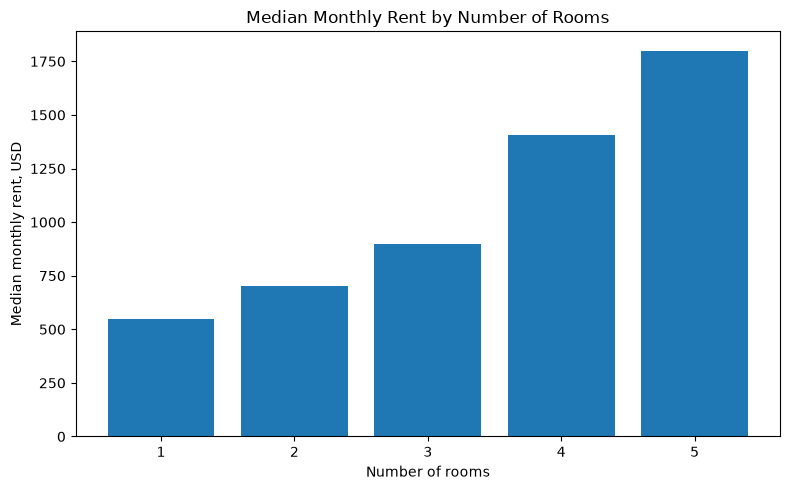

In [19]:
_, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    rent_by_rooms["rooms"].astype(str),
    rent_by_rooms["median_rent_usd"],
)

ax.set_title("Median Monthly Rent by Number of Rooms")
ax.set_xlabel("Number of rooms")
ax.set_ylabel("Median monthly rent, USD")

plt.tight_layout()
plt.show()

Rental prices increase consistently with apartment size. The median rent ranges from **\$550 for one-room apartments** to **\$1,800 for five-room apartments**.

The overall median of **\$700** is not driven only by a small number of luxury listings: one- and two-room apartments already show relatively high median asking rents.

## 3. Location and Pricing

### Rental Prices by District

Rental prices are compared across Minsk administrative districts using both total monthly rent and rent per square meter.

In [20]:
district_summary = (
    listings.dropna(subset=["district"])
    .groupby("district", as_index=False)
    .agg(
        listings_count=("ad_code", "count"),
        median_rent_usd=("price_usd", "median"),
        median_price_per_m2_usd=("price_per_m2_usd", "median"),
    )
    .sort_values("median_rent_usd", ascending=False)
)

district_summary

,district,listings_count,median_rent_usd,median_price_per_m2_usd
0,Central,332,934.0,14.285714
6,Pervomaisky,229,713.0,13.333333
7,Sovetsky,166,708.0,11.928690
4,Oktyabrsky,265,668.0,15.503876
3,Moskovsky,205,657.0,12.600000
5,Partizansky,60,656.0,12.121212
2,Leninsky,88,647.5,11.227179
1,Frunzensky,217,600.0,11.032609
8,Zavodskoy,40,504.5,10.745074


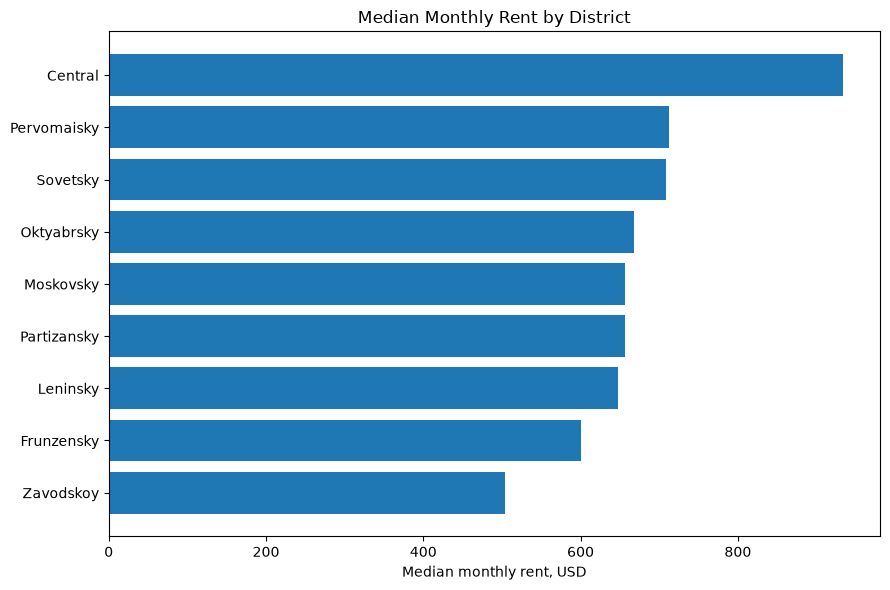

In [21]:
district_plot = district_summary.sort_values(
    "median_rent_usd",
    ascending=True,
)

_, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    district_plot["district"],
    district_plot["median_rent_usd"],
)

ax.set_title("Median Monthly Rent by District")
ax.set_xlabel("Median monthly rent, USD")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

Central and Pervomaisky districts have the highest median asking rents, while Zavodskoy and Frunzensky are the most affordable.

However, total monthly rent does not fully reflect location intensity. Oktyabrsky district has a lower median monthly rent than Central or Pervomaisky, but the highest median rent per square meter, showing that total monthly rent alone does not capture district-level pricing differences.

### Rent per Square Meter by District

Rent per square meter provides a complementary view of district pricing by accounting for apartment size.

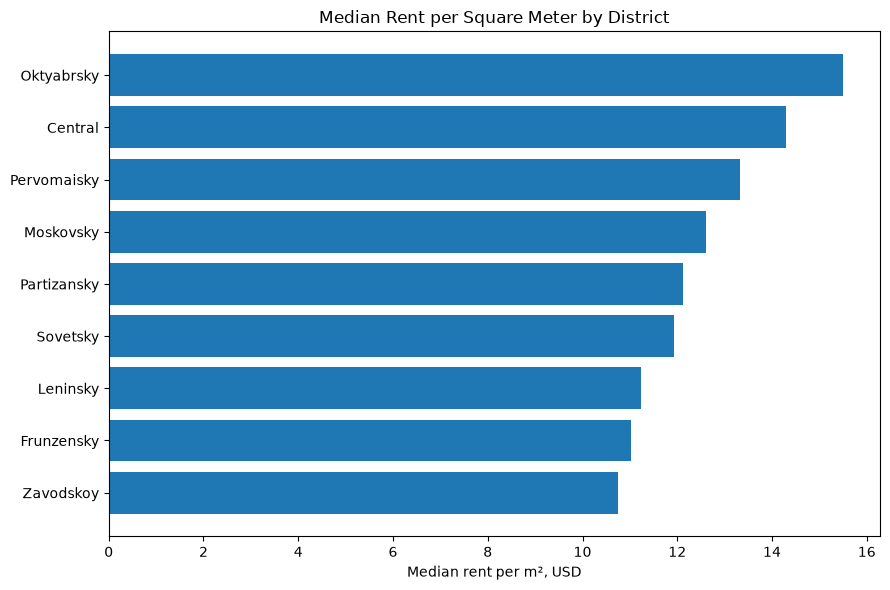

In [22]:
district_m2_plot = district_summary.sort_values(
    "median_price_per_m2_usd",
    ascending=True,
)

_, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    district_m2_plot["district"],
    district_m2_plot["median_price_per_m2_usd"],
)

ax.set_title("Median Rent per Square Meter by District")
ax.set_xlabel("Median rent per m², USD")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

Oktyabrsky district has the highest median rent per square meter at approximately **\$15.5/m²**, despite ranking below Central and Pervomaisky districts in total monthly rent.

This indicates that district-level affordability depends not only on total rent but also on apartment size and housing composition. Central and Pervomaisky remain expensive overall, while Oktyabrsky stands out for relatively high spatial pricing.

### Metro Accessibility

Listings are compared by the reported mode of access to the nearest metro station to assess whether better metro accessibility is associated with higher asking rents.

In [23]:
metro_summary = (
    listings.assign(
        metro_access=listings["metro_time_mode"].fillna("not specified")
    )
    .groupby("metro_access", as_index=False)
    .agg(
        listings_count=("ad_code", "count"),
        median_rent_usd=("price_usd", "median"),
        median_price_per_m2_usd=("price_per_m2_usd", "median"),
    )
    .sort_values("median_rent_usd", ascending=False)
)

metro_summary

,metro_access,listings_count,median_rent_usd,median_price_per_m2_usd
0,not specified,1211,700.0,12.765957
2,walk,371,700.0,14.444444
1,transport,42,577.0,11.349000


Listings with reported walking access to the metro have the highest median rent per square meter at approximately **\$14.4/m²**.

However, the `not specified` category contains most listings and should not be interpreted as poor metro accessibility. The `transport` group is also small, so differences between access categories should be interpreted cautiously.

## 4. Listing Characteristics

### Rental Prices by Repair State

Median rent and rent per square meter are compared across reported apartment repair conditions.

In [24]:
repair_summary = (
    listings.dropna(subset=["repair_state"])
    .groupby("repair_state", as_index=False)
    .agg(
        listings_count=("ad_code", "count"),
        median_rent_usd=("price_usd", "median"),
        median_price_per_m2_usd=("price_per_m2_usd", "median"),
    )
    .sort_values("median_rent_usd", ascending=False)
)

repair_summary

,repair_state,listings_count,median_rent_usd,median_price_per_m2_usd
1,excellent,34,825.0,16.523214
0,euro,955,781.0,14.285714
2,good,428,605.5,11.446558
4,poor,3,509.0,6.081081
3,normal,105,500.0,10.651163


Better reported repair condition is associated with higher median asking rents, although the smallest condition categories contain too few listings for reliable comparison.

### Furnished vs Unfurnished Listings

Median asking rents are compared between furnished and unfurnished apartments.

In [25]:
furniture_summary = (
    listings.groupby("has_furniture", as_index=False)
    .agg(
        listings_count=("ad_code", "count"),
        median_rent_usd=("price_usd", "median"),
        median_price_per_m2_usd=("price_per_m2_usd", "median"),
        median_area_m2=("area_total_m2", "median"),
    )
)

furniture_summary

,has_furniture,listings_count,median_rent_usd,median_price_per_m2_usd,median_area_m2
0,False,119,662.0,12.962963,55.0
1,True,1505,700.0,13.092169,55.0


Furnished listings have a modestly higher median monthly asking rent than unfurnished listings (**\$700** vs **\$662**), while median rent per square meter is nearly identical (**\$13.09** vs **\$12.96**).

These comparisons do not isolate the effect of furniture availability from other apartment characteristics.

### Agency vs Private Listings

Asking rents are compared between listings classified as agency and private based on the presence of explicit agency metadata.

In [26]:
seller_summary = (
    listings.groupby("seller_type", as_index=False)
    .agg(
        listings_count=("ad_code", "count"),
        median_rent_usd=("price_usd", "median"),
        median_price_per_m2_usd=("price_per_m2_usd", "median"),
        median_area_m2=("area_total_m2", "median"),
    )
)

seller_summary

,seller_type,listings_count,median_rent_usd,median_price_per_m2_usd,median_area_m2
0,agency,376,800.0,13.554340,63.35
1,private,1248,679.0,12.903226,52.00


Agency listings have a higher median monthly asking rent than private listings (**\$800** vs **\$679**), but they also represent larger apartments, with median areas of **63.35 m²** and **52 m²**, respectively.

The difference in median rent per square meter is smaller (**\$13.55** vs **\$12.90**, or approximately **5%**). These comparisons do not isolate the effect of seller type from differences in apartment size, location, and other listing characteristics.

Listings with explicit agency metadata were classified as agency listings; all remaining listings were treated as private listings.

## 5. Recorded Price Changes

The source provides recorded price history for a subset of listings. These records are used to examine how often asking prices were changed and whether increases or decreases were more common.

A `status` value of `0` represents a baseline record in the available source history, while `1` and `-1` indicate recorded price increases and decreases.

In [27]:
price_change_summary = (
    price_history["status"]
    .value_counts()
    .rename_axis("status")
    .reset_index(name="records")
    .sort_values("status")
)

price_change_summary

,status,records
0,-1,1887
1,0,1614
2,1,1162


In [28]:
listing_change_summary = (
    price_history.groupby("ad_code")
    .agg(
        history_records=("recorded_at", "count"),
        increases=("status", lambda x: (x == 1).sum()),
        decreases=("status", lambda x: (x == -1).sum()),
    )
)

listings_with_history = listing_change_summary.shape[0]
listings_with_changes = (
    (listing_change_summary["increases"] > 0)
    | (listing_change_summary["decreases"] > 0)
).sum()

print("Listings with recorded price history:", listings_with_history)
print("Listings with at least one recorded price change:", listings_with_changes)
print(f"Share with recorded changes: {listings_with_changes / listings_with_history:.1%}")

Listings with recorded price history: 1585
Listings with at least one recorded price change: 832
Share with recorded changes: 52.5%


Recorded price history is available for **1,585 listings**. Of these, **832 listings (52.5%)** contain at least one recorded increase or decrease.

Across all recorded change events, price decreases are more common than increases. However, individual listings may contain multiple price changes, so event counts alone do not show how many apartments experienced each type of adjustment.

In [29]:
def classify_price_changes(row):
    if row["increases"] > 0 and row["decreases"] > 0:
        return "both"
    if row["increases"] > 0:
        return "increase only"
    if row["decreases"] > 0:
        return "decrease only"
    return "no recorded change"


listing_change_summary["change_type"] = (
    listing_change_summary.apply(classify_price_changes, axis=1)
)

change_type_summary = (
    listing_change_summary["change_type"]
    .value_counts()
    .rename_axis("change_type")
    .reset_index(name="listings")
)

change_type_summary

,change_type,listings
0,no recorded change,753
1,both,360
2,decrease only,306
3,increase only,166


Among listings with recorded price changes, the most common pattern is a combination of both increases and decreases. Listings that experienced at least one decrease are also somewhat more common than listings that experienced at least one increase, suggesting that asking prices are actively adjusted in both directions rather than following a simple one-way pattern.

In [30]:
price_history_sorted = price_history.sort_values(
    ["ad_code", "recorded_at"]
).copy()

price_history_sorted["previous_price"] = (
    price_history_sorted.groupby("ad_code")["price_listed"].shift()
)

price_history_sorted["previous_currency"] = (
    price_history_sorted.groupby("ad_code")["price_currency"].shift()
)

same_currency_changes = price_history_sorted.loc[
    (price_history_sorted["status"] != 0)
    & (
        price_history_sorted["price_currency"]
        == price_history_sorted["previous_currency"]
    )
].copy()

same_currency_changes["change_pct"] = (
    (
        same_currency_changes["price_listed"]
        - same_currency_changes["previous_price"]
    )
    / same_currency_changes["previous_price"]
    * 100
)

In [31]:
change_direction_summary = (
    same_currency_changes.assign(
        direction=same_currency_changes["status"].map(
            {-1: "decrease", 1: "increase"}
        )
    )
    .groupby("direction")["change_pct"]
    .agg(
        records="count",
        median="median",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
    )
)

change_direction_summary.round(1)

,records,median,q1,q3
direction,,,,
decrease,1777,-5.2,-8.7,-1.4
increase,1031,9.1,3.6,20.1


Recorded price increases tend to be larger than decreases. The median increase is approximately **9.1%**, compared with a median decrease of **5.2%** in absolute terms.

Median and quartile statistics are used instead of the mean because the source history contains several extreme price adjustments that would strongly distort average percentage changes.

### Frequency of Price Adjustments

The number of recorded price changes per listing is examined to understand whether asking prices are typically adjusted once or revised multiple times.

In [32]:
listing_change_summary["change_events"] = (
    listing_change_summary["increases"]
    + listing_change_summary["decreases"]
)

change_events = listing_change_summary.loc[
    listing_change_summary["change_events"] > 0,
    "change_events",
]

price_adjustment_frequency = pd.Series(
    {
        "Listings with price changes": len(change_events),
        "Median changes per listing": change_events.median(),
        "Changed once, %": (change_events == 1).mean() * 100,
        "Changed multiple times, %": (change_events >= 2).mean() * 100,
        "Maximum recorded changes": change_events.max(),
    }
)

price_adjustment_frequency.round(1)

Listings with price changes    832.0
Median changes per listing       2.0
Changed once, %                 38.7
Changed multiple times, %       61.3
Maximum recorded changes        58.0
dtype: float64

Price adjustments are often not one-time events. Among listings with recorded price changes, **61.3%** were revised multiple times, with a median of two changes per listing. A small number of listings show substantially more frequent repricing.

### Price Adjustments by Market Segment

Listings are divided into three price segments based on tertiles of their current asking rent to examine whether repricing activity differs across the market.

The segment cutoffs are **\$600** and **\$832**. Listings with the same asking rent are kept in the same segment, so group sizes may differ.

In [33]:
listings["price_segment"] = pd.qcut(
    listings["price_usd"],
    q=3,
    labels=["lower", "middle", "higher"],
)

change_by_listing = (
    listing_change_summary
    .reset_index()
    .assign(
        has_price_change=lambda df: df["change_events"] > 0
    )
)

segment_changes = (
    listings[
        ["ad_code", "price_usd", "price_segment"]
    ]
    .merge(
        change_by_listing[
            ["ad_code", "has_price_change"]
        ],
        on="ad_code",
        how="inner",
    )
    .groupby(
        "price_segment",
        observed=True,
        as_index=False,
    )
    .agg(
        listings_count=("ad_code", "count"),
        median_rent_usd=("price_usd", "median"),
        listings_with_changes=("has_price_change", "sum"),
        share_with_changes=("has_price_change", "mean"),
    )
)

segment_changes["share_with_changes"] *= 100

segment_changes.round(1)

,price_segment,listings_count,median_rent_usd,listings_with_changes,share_with_changes
0,lower,554,509.0,251,45.3
1,middle,510,700.0,273,53.5
2,higher,521,1086.0,308,59.1


Among listings with available price history, price adjustment activity is highest in the higher price segment, where **59.1%** have at least one recorded price change. The share is **53.5%** in the middle segment and **45.3%** in the lower segment.

In this snapshot, the share of listings with recorded price changes increases across the three current asking-price segments. These differences may reflect listing composition and the length of available price history as well as seller behavior.

### Direction of Price Changes by Market Segment

The share of listings with recorded price increases and decreases is compared across price segments to examine whether seller behavior differs between lower-, middle-, and higher-priced apartments.

In [34]:
segment_direction = (
    listings[
        ["ad_code", "price_segment"]
    ]
    .merge(
        listing_change_summary.reset_index()[
            ["ad_code", "increases", "decreases"]
        ],
        on="ad_code",
        how="inner",
    )
    .assign(
        had_increase=lambda df: df["increases"] > 0,
        had_decrease=lambda df: df["decreases"] > 0,
    )
    .groupby(
        "price_segment",
        observed=True,
        as_index=False,
    )
    .agg(
        listings_count=("ad_code", "count"),
        share_with_increase=("had_increase", "mean"),
        share_with_decrease=("had_decrease", "mean"),
    )
)

segment_direction[
    ["share_with_increase", "share_with_decrease"]
] *= 100

segment_direction.round(1)

,price_segment,listings_count,share_with_increase,share_with_decrease
0,lower,554,29.2,35.4
1,middle,510,31.6,44.1
2,higher,521,39.0,47.0


Among listings with available price history, recorded decreases are more common than increases in all three price segments.

The higher segment has the largest share of listings with at least one recorded decrease (**47.0%**) and the largest share with at least one recorded increase (**39.0%**). The middle segment has the largest gap between the two shares: **44.1%** experienced a decrease, compared with **31.6%** that experienced an increase. In the lower segment, the corresponding shares are **35.4%** and **29.2%**.

These results distinguish overall repricing activity, which is highest in the higher segment, from the larger imbalance toward recorded decreases in the middle segment.

## 6. Combined Pricing Analysis

Single-factor comparisons can be influenced by differences in apartment composition across districts. To better isolate location effects, rental prices are compared within apartments of the same room count.

The analysis focuses on one-, two-, and three-room apartments, which represent the largest market segments and provide more reliable district-level comparisons.

### Rent by District and Number of Rooms

In [35]:
district_room_summary = (
    listings.dropna(subset=["district"])
    .loc[lambda df: df["rooms"].isin([1, 2, 3])]
    .groupby(
        ["district", "rooms"],
        as_index=False,
    )
    .agg(
        listings_count=("ad_code", "count"),
        median_rent_usd=("price_usd", "median"),
        median_price_per_m2_usd=("price_per_m2_usd", "median"),
        median_area_m2=("area_total_m2", "median"),
    )
    .sort_values(
        ["rooms", "median_rent_usd"],
        ascending=[True, False],
    )
)

district_room_summary.round(1)

,district,rooms,listings_count,median_rent_usd,median_price_per_m2_usd,median_area_m2
0,Central,1,53,611.0,14.8,40.5
9,Moskovsky,1,65,600.0,13.1,43.0
18,Pervomaisky,1,58,600.0,14.7,40.5
12,Oktyabrsky,1,99,565.0,18.3,32.0
21,Sovetsky,1,37,509.0,13.9,37.1
24,Zavodskoy,1,13,509.0,13.7,32.9
15,Partizansky,1,16,500.5,13.1,40.0
3,Frunzensky,1,80,500.0,12.3,40.8
6,Leninsky,1,22,475.0,12.3,36.0
1,Central,2,145,850.0,15.2,58.5


In [36]:
reliable_districts = (
    district_room_summary
    .groupby("district")
    .filter(
        lambda group: (
            (group["rooms"].nunique() == 3)
            and (group["listings_count"] >= 20).all()
        )
    )
)

rent_by_district_rooms = (
    reliable_districts
    .pivot(
        index="district",
        columns="rooms",
        values="median_rent_usd",
    )
    .rename(
        columns={
            1: "1 room",
            2: "2 rooms",
            3: "3 rooms",
        }
    )
)

rent_by_district_rooms

rooms,1 room,2 rooms,3 rooms
district,,,
Central,611.0,850.0,1100.0
Frunzensky,500.0,600.0,775.0
Leninsky,475.0,650.0,836.0
Moskovsky,600.0,700.0,875.0
Oktyabrsky,565.0,699.5,876.0
Pervomaisky,600.0,713.0,822.5
Sovetsky,509.0,700.0,799.0


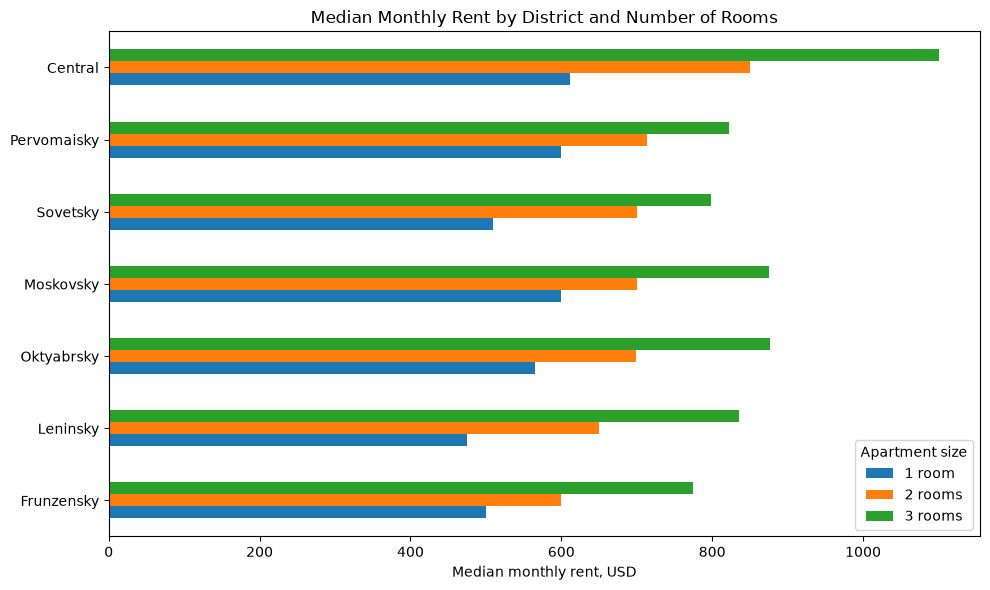

In [37]:
rent_by_district_rooms_plot = (
    rent_by_district_rooms
    .sort_values("2 rooms")
)

ax = rent_by_district_rooms_plot.plot(
    kind="barh",
    figsize=(10, 6),
)

ax.set_title("Median Monthly Rent by District and Number of Rooms")
ax.set_xlabel("Median monthly rent, USD")
ax.set_ylabel("")
ax.legend(title="Apartment size")

plt.tight_layout()
plt.show()

Location differences remain visible even when apartments are compared within the same room-count category.

Central district has the highest median asking rent for one-, two-, and three-room apartments among districts with sufficient observations, at **\$611**, **\$850**, and **\$1,100**, respectively. Frunzensky district remains one of the more affordable locations across all three apartment sizes.

This indicates that district-level price differences persist even when apartments are compared within the same room-count category.

### Distance to Central Minsk

To examine the location premium more directly, the straight-line distance from each listing to the Zero Kilometer monument on October Square is calculated using listing coordinates.

The monument (`53.9022, 27.5614`) is used as a reproducible reference point for central Minsk rather than as the exact geographic center of the city.


In [38]:
from math import asin, cos, radians, sin, sqrt


CENTER_LAT = 53.9022
CENTER_LON = 27.5614


def haversine_distance_km(lat, lon, center_lat=CENTER_LAT, center_lon=CENTER_LON):
    earth_radius_km = 6371.0

    lat1 = radians(lat)
    lon1 = radians(lon)
    lat2 = radians(center_lat)
    lon2 = radians(center_lon)

    delta_lat = lat2 - lat1
    delta_lon = lon2 - lon1

    a = (
        sin(delta_lat / 2) ** 2
        + cos(lat1) * cos(lat2) * sin(delta_lon / 2) ** 2
    )

    return 2 * earth_radius_km * asin(sqrt(a))


listings["distance_to_center_km"] = listings.apply(
    lambda row: haversine_distance_km(
        row["latitude"],
        row["longitude"],
    ),
    axis=1,
)

listings["distance_to_center_km"].describe()

count    1624.000000
mean        4.927494
std         2.555041
min         0.156116
25%         3.072420
50%         4.463518
75%         6.733887
max        22.577326
Name: distance_to_center_km, dtype: float64

In [39]:
listings["center_distance_zone"] = pd.cut(
    listings["distance_to_center_km"],
    bins=[0, 3, 5, 7, float("inf")],
    labels=[
        "0–3 km",
        "3–5 km",
        "5–7 km",
        "7+ km",
    ],
    right=False,
)

distance_summary = (
    listings.groupby(
        "center_distance_zone",
        observed=True,
        as_index=False,
    )
    .agg(
        listings_count=("ad_code", "count"),
        median_rent_usd=("price_usd", "median"),
        median_price_per_m2_usd=("price_per_m2_usd", "median"),
        median_area_m2=("area_total_m2", "median"),
    )
)

distance_summary.round(1)

,center_distance_zone,listings_count,median_rent_usd,median_price_per_m2_usd,median_area_m2
0,0–3 km,389,800.0,13.5,61.0
1,3–5 km,566,679.0,14.4,47.8
2,5–7 km,311,700.0,12.6,57.8
3,7+ km,358,600.0,11.3,57.0


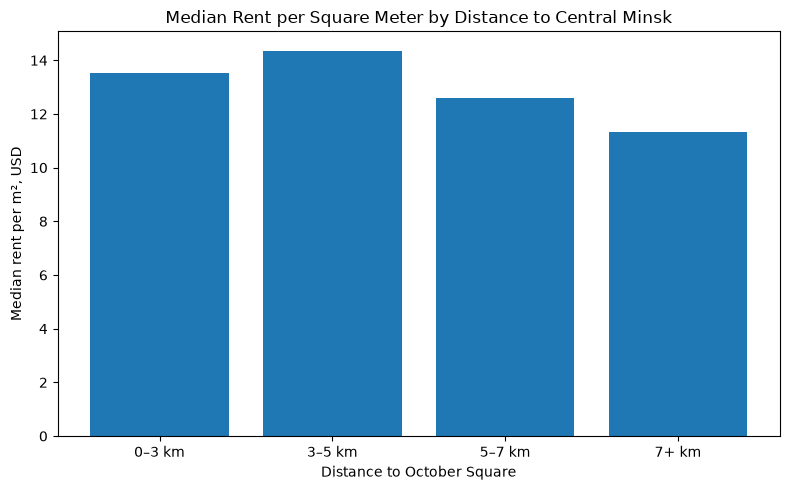

In [40]:
_, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    distance_summary["center_distance_zone"].astype(str),
    distance_summary["median_price_per_m2_usd"],
)

ax.set_title("Median Rent per Square Meter by Distance to Central Minsk")
ax.set_xlabel("Distance to October Square")
ax.set_ylabel("Median rent per m², USD")

plt.tight_layout()
plt.show()

Listings within **5 km of October Square** have higher median rent per square meter than listings located farther away.

The median is approximately **\$13.5/m²** within 3 km and **\$14.4/m²** between 3 and 5 km. It falls to about **\$12.6/m²** between 5 and 7 km and **\$11.3/m²** beyond 7 km.

Prices do not decline uniformly with distance: the 3–5 km zone has a higher median rent per square meter than the zone within 3 km. Differences in apartment size and listing composition should be considered when interpreting these comparisons.

### Relationship Between Distance and Rental Price

The relationship between distance to central Minsk and rental pricing is examined across individual listings using Spearman rank correlation.

In [41]:
distance_rank = listings["distance_to_center_km"].rank()

distance_correlations = pd.Series(
    {
        "Rent, USD": distance_rank.corr(
            listings["price_usd"].rank()
        ),
        "Rent per m², USD": distance_rank.corr(
            listings["price_per_m2_usd"].rank()
        ),
    }
)

distance_correlations.round(3)

Rent, USD          -0.241
Rent per m², USD   -0.189
dtype: float64

In [42]:
distance_by_rooms = (
    listings.loc[
        listings["rooms"].isin([1, 2, 3])
    ]
    .groupby("rooms")
    .apply(
        lambda group: pd.Series(
            {
                "listings_count": len(group),
                "rent_correlation": (
                    group["distance_to_center_km"]
                    .rank()
                    .corr(group["price_usd"].rank())
                ),
                "price_per_m2_correlation": (
                    group["distance_to_center_km"]
                    .rank()
                    .corr(group["price_per_m2_usd"].rank())
                ),
            }
        ),
        include_groups=False,
    )
)

distance_by_rooms.round(3)

,listings_count,rent_correlation,price_per_m2_correlation
rooms,,,
1,452.0,-0.241,-0.329
2,666.0,-0.228,-0.230
3,401.0,-0.252,-0.210


The negative relationship between distance and rental prices remains visible within one-, two-, and three-room apartments.

The association is strongest for one-room apartments, where the Spearman correlation between distance and rent per square meter is approximately **−0.33**. Similar negative relationships are also observed for two- and three-room apartments.

This suggests that the central location premium is not driven solely by differences in room-count composition.

### Rent per Square Meter by District and Number of Rooms

Rent per square meter is compared within the same room-count categories to reduce the influence of apartment size when examining district-level pricing differences.

In [43]:
price_per_m2_by_district_rooms = (
    reliable_districts
    .pivot(
        index="district",
        columns="rooms",
        values="median_price_per_m2_usd",
    )
    .rename(
        columns={
            1: "1 room",
            2: "2 rooms",
            3: "3 rooms",
        }
    )
)

price_per_m2_by_district_rooms.round(1)

rooms,1 room,2 rooms,3 rooms
district,,,
Central,14.8,15.2,14.0
Frunzensky,12.3,10.5,9.7
Leninsky,12.3,12.0,10.3
Moskovsky,13.1,12.6,10.6
Oktyabrsky,18.3,14.9,13.5
Pervomaisky,14.7,13.4,10.6
Sovetsky,13.9,13.4,10.2


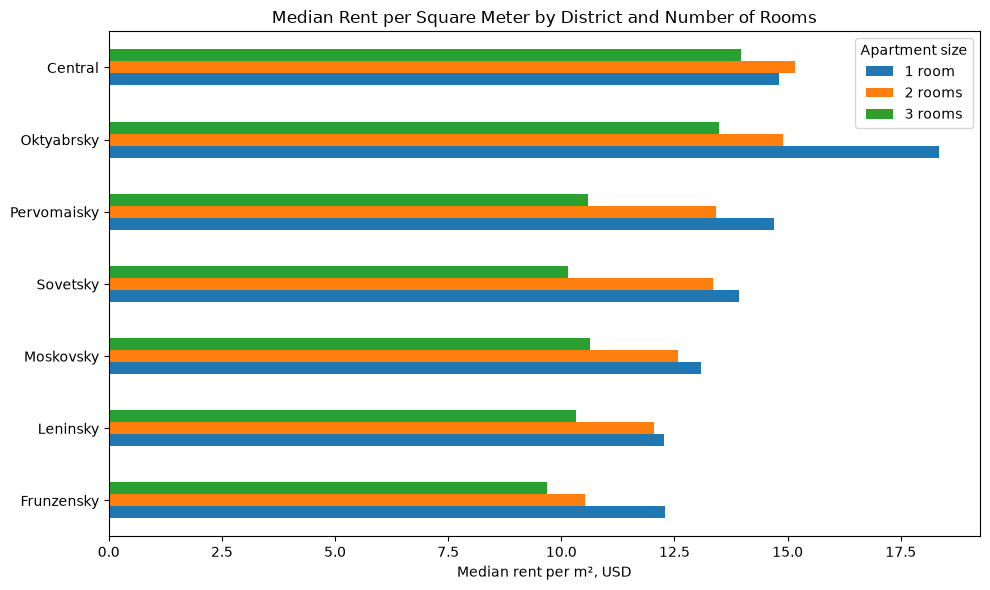

In [44]:
price_per_m2_plot = (
    price_per_m2_by_district_rooms
    .sort_values("2 rooms")
)

ax = price_per_m2_plot.plot(
    kind="barh",
    figsize=(10, 6),
)

ax.set_title(
    "Median Rent per Square Meter by District and Number of Rooms"
)
ax.set_xlabel("Median rent per m², USD")
ax.set_ylabel("")
ax.legend(title="Apartment size")

plt.tight_layout()
plt.show()

Among districts with sufficient observations, Oktyabrsky district has the highest median rent per square meter for one-room apartments at approximately **\$18.3/m²**. Central district has the highest medians for two- and three-room apartments, at approximately **\$15.2/m²** and **\$14.0/m²**, respectively.

Frunzensky district remains consistently more affordable, particularly for two- and three-room apartments.

These results reinforce the presence of a location premium that persists even when apartment room count is held constant.

## 7. Snapshot Comparison: September vs October

A second market snapshot was collected on **October 28, 2026**, approximately seven weeks after the initial **September 5, 2026** snapshot.

The comparison highlights several differences between the observed listings:

- The number of active listings increased from **1,551 to 1,624**.

- The median monthly asking rent was **\$700 in both snapshots**, while the median rent per square meter increased slightly from approximately **\$12.8/m²** to **\$13.1/m²**.

- District-level medians changed unevenly. Median monthly rent in **Pervomaisky district** decreased from **\$798** to **\$713**, while **Oktyabrsky** increased from **\$645** to **\$668** and **Frunzensky** increased from **\$585** to **\$600**.

- Among listings with available price history, the share with at least one recorded price change increased from **50.5% to 52.5%**. Among listings with recorded price changes, the share revised multiple times increased from **56.6% to 61.3%**.

- Recorded decreases accounted for **53.7%** of all recorded increases and decreases in the September snapshot, compared with **61.9%** in October. The **higher price segment** had the largest share of listings with recorded price changes in October, whereas the middle segment had the largest share in September.

The October snapshot contains a higher share of recorded decreases among all recorded price changes. However, the available histories cover different periods and do not isolate price adjustments made between the two collection dates.

The two snapshots contain different sets of active listings. Differences may therefore reflect both changes in asking prices and changes in listing composition. The comparison does not track the same apartments over time.


## 8. Key Findings

* The median asking rent in the snapshot is **\$700 per month**, with a median rent of approximately **\$13.1/m²**. Rental prices are right-skewed, so median values provide a more representative measure than the mean.

* Location remains an important pricing factor even within comparable room-count categories. **Central district** has the highest median monthly rent across one-, two-, and three-room apartments among districts with sufficient observations. **Oktyabrsky district** has the highest median rent per square meter for one-room apartments, while Central district leads for two- and three-room apartments.

* A central-location premium is visible beyond administrative district boundaries. Listings within **5 km of October Square** have median rents per square meter of approximately **\$13.5 – 14.4/m²** across the two distance zones, compared with approximately **\$11.3–12.6/m²** in the zones farther away. A modest negative relationship between distance and rental price also remains visible within one-, two-, and three-room apartments.

* Agency listings have a higher median monthly rent than private listings (**\$800** vs **\$679**), but they also represent larger apartments. The difference in median rent per square meter is smaller (**\$13.55** vs **\$12.90**). These comparisons do not isolate the effect of seller type from differences in listing composition.

* Price adjustments are common: **52.5%** of listings with available price history contain at least one recorded increase or decrease, and **61.3%** of listings with price changes were repriced more than once. Median recorded increases are larger than decreases in absolute terms (**+9.1% vs −5.2%**).

* The **higher price segment** has the highest share of listings with recorded price changes (**59.1%**), compared with **53.5%** in the middle segment and **45.3%** in the lower segment. Recorded decreases are more common than increases in all three segments, while the **middle segment** has the largest gap between the shares with decreases and increases (**44.1% vs 31.6%**).

## 9. Practical Implications

The findings suggest several practical approaches for landlords and rental agencies when setting and adjusting asking prices.

### 1. Use Comparable Listings for Initial Pricing

Asking prices should be benchmarked against apartments with similar location, room count, and overall characteristics rather than against the city-wide market alone.

### 2. Incorporate Location More Precisely Than District Alone

Administrative district is useful for market comparison, but proximity to central Minsk provides additional pricing information. Location benchmarking should therefore consider both district and distance from central Minsk.

### 3. Reassess Asking Prices After Publication

Repeated price changes are common in the recorded history, suggesting that asking prices are frequently revised after listings enter the market.

Landlords and agencies can periodically compare active listings with similar properties and reassess their asking price as the competitive set changes.

### 4. Consider Differences in Repricing Across Market Segments

The higher price segment shows the greatest overall repricing activity, while the middle segment has the largest gap between the shares of listings with recorded decreases and increases.

Landlords and agencies can use these differences as context when reviewing comparable listings and reassessing asking prices. Recorded adjustments should be interpreted alongside property characteristics and current competition.

### 5. Prioritize Comparable Property Characteristics

Location and room count show clear pricing differences across the analyzed listings, while furniture availability and seller type show much smaller differences in median rent per square meter.

Market comparisons should therefore begin with location and room count, with other listing characteristics used as additional context.

## 10. Limitations

* The analysis is based on a single Realt.by snapshot collected on **October 28, 2026**. The results therefore describe the observed listings on this platform rather than the entire Minsk rental market.

* Asking prices are analyzed instead of completed rental transactions. Final negotiated rents may differ from the prices shown in listings.

* Listings with explicit agency metadata were classified as agency listings; all remaining listings were treated as private listings. This is an analytical classification and may not perfectly identify every seller type.

* The source price history may be incomplete and can contain large historical adjustments or corrections. Price-change analysis therefore relies primarily on median and quartile statistics and compares percentage changes only when consecutive prices are recorded in the same currency.

* The Zero Kilometer monument on October Square is used as a reproducible reference point for central Minsk. Distance to this point should be interpreted as a proxy for centrality rather than an exact measure of accessibility or neighborhood quality.

* Some listing attributes contain missing or inconsistent source values. Clearly implausible structural values were treated as missing, while observations that could not be confidently identified as errors were retained.